In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

analyzer = SentimentIntensityAnalyzer()

print(df[["headline", "body_text", "label"]].head())

                                     headline  \
0              Global economy faces recession   
1   Earthquake hits Chittagong, panic spreads   
2  Breakthrough in Bangladesh's tech industry   
3     Dengue situation worsens in the country   
4              New virus outbreak sparks fear   

                                           body_text label  
0  The Prime Minister attended the inauguration c...  Real  
1  Government sources state that an official anno...  Real  
2  Local administration has visited the spot for ...  Fake  
3  The Prime Minister attended the inauguration c...  Fake  
4  Government sources state that an official anno...  Real  


In [2]:
def get_sentiment(text):
    return analyzer.polarity_scores(text)

headline_scores = df["headline"].apply(get_sentiment)
body_scores = df["body_text"].apply(get_sentiment)

headline_sentiment = pd.DataFrame(headline_scores.tolist()).add_prefix("headline_")
body_sentiment = pd.DataFrame(body_scores.tolist()).add_prefix("body_")

df = pd.concat([df, headline_sentiment, body_sentiment], axis=1)

print(df[[
    "headline_compound",
    "body_compound",
    "headline_neg",
    "body_neg"
]].head())

   headline_compound  body_compound  headline_neg  body_neg
0            -0.4215            0.0         0.483       0.0
1            -0.5106            0.0         0.452       0.0
2             0.0000            0.0         0.000       0.0
3            -0.4767            0.0         0.383       0.0
4            -0.4939            0.0         0.444       0.0


In [3]:
df["sentiment_difference"] = (
    df["headline_compound"] - df["body_compound"]
)

def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["headline_tone"] = df["headline_compound"].apply(classify_sentiment)
df["body_tone"] = df["body_compound"].apply(classify_sentiment)

df["tone_match"] = df["headline_tone"] == df["body_tone"]

df["framing_difference"] = df["sentiment_difference"].apply(
    lambda x: "Headline more positive" if x > 0.05
    else "Headline more negative" if x < -0.05
    else "Similar sentiment"
)

print(df[[
    "headline", "headline_tone", "body_tone",
    "sentiment_difference", "framing_difference"
]].head(10))

                                     headline headline_tone body_tone  \
0              Global economy faces recession      Negative   Neutral   
1   Earthquake hits Chittagong, panic spreads      Negative   Neutral   
2  Breakthrough in Bangladesh's tech industry       Neutral   Neutral   
3     Dengue situation worsens in the country      Negative   Neutral   
4              New virus outbreak sparks fear      Negative   Neutral   
5   Earthquake hits Chittagong, panic spreads      Negative  Negative   
6              Global economy faces recession      Negative   Neutral   
7              Global economy faces recession      Negative  Negative   
8   Earthquake hits Chittagong, panic spreads      Negative  Negative   
9        New curriculum introduced in schools       Neutral   Neutral   

   sentiment_difference      framing_difference  
0               -0.4215  Headline more negative  
1               -0.5106  Headline more negative  
2                0.0000       Similar sentimen

In [4]:
sentiment_comparison = df.groupby("label")[
    [
        "headline_pos", "headline_neg", "headline_neu",
        "body_pos", "body_neg", "body_neu",
        "headline_compound", "body_compound"
    ]
].mean().round(3)

print(sentiment_comparison)

       headline_pos  headline_neg  headline_neu  body_pos  body_neg  body_neu  \
label                                                                           
Fake          0.071         0.172         0.757     0.060     0.092     0.849   
Real          0.085         0.181         0.734     0.056     0.083     0.861   

       headline_compound  body_compound  
label                                    
Fake              -0.117         -0.079  
Real              -0.109         -0.070  


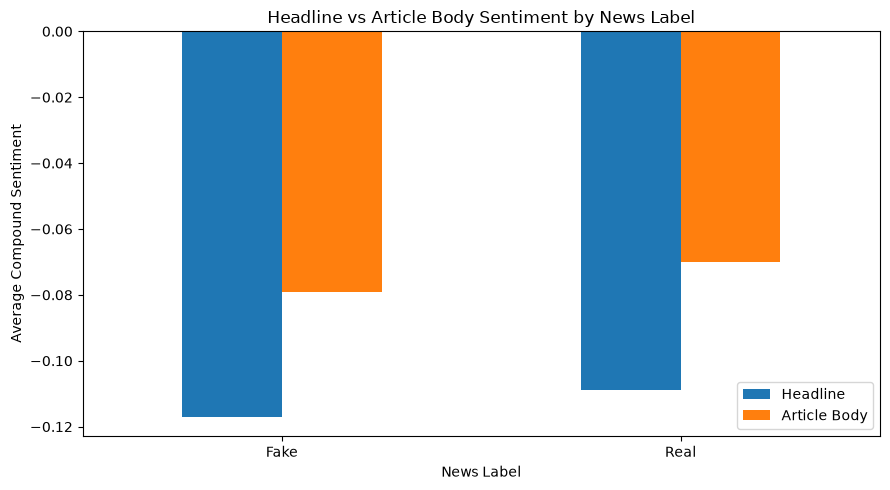

In [5]:
sentiment_comparison[
    ["headline_compound", "body_compound"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Headline vs Article Body Sentiment by News Label")
plt.xlabel("News Label")
plt.ylabel("Average Compound Sentiment")
plt.xticks(rotation=0)
plt.legend(["Headline", "Article Body"])
plt.tight_layout()
plt.show()

framing_difference  Headline more negative  Headline more positive  \
label                                                                
Fake                                 42.79                   32.61   
Real                                 43.65                   32.94   

framing_difference  Similar sentiment  
label                                  
Fake                            24.59  
Real                            23.41  


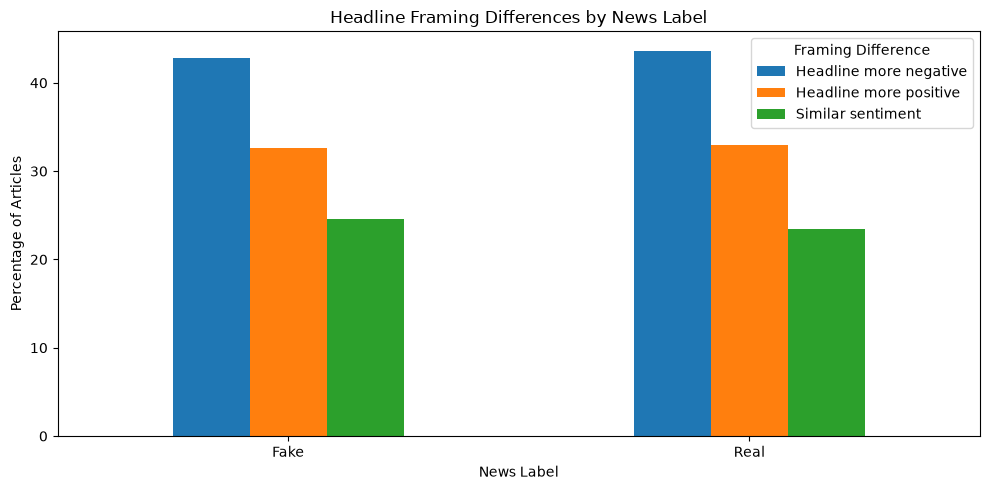

In [6]:
framing_comparison = pd.crosstab(
    df["label"],
    df["framing_difference"],
    normalize="index"
) * 100

print(framing_comparison.round(2))

framing_comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Headline Framing Differences by News Label")
plt.xlabel("News Label")
plt.ylabel("Percentage of Articles")
plt.xticks(rotation=0)
plt.legend(title="Framing Difference")
plt.tight_layout()
plt.show()

In [7]:
df.to_csv("T33_headline_body_sentiment.csv", index=False)
sentiment_comparison.to_csv("T33_sentiment_comparison.csv")
framing_comparison.to_csv("T33_framing_comparison.csv")

print("Task 32 results saved successfully.")

Task 32 results saved successfully.
